In [1]:
from pathlib import Path

import pandas as pd
from PIL import Image, UnidentifiedImageError


DATASET_DIR = Path("../data/classification")
ALLOWED_EXTENSIONS = {".jpeg", ".jpg", ".bmp", ".png"}


def load_dataset(dataset_dir: Path) -> pd.DataFrame:
    records = []

    if not dataset_dir.exists():
        raise FileNotFoundError(f"Dataset directory not found: {dataset_dir}")

    for file_path in dataset_dir.rglob("*"):
        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in ALLOWED_EXTENSIONS:
            print(f"[REJECTED: extension] {file_path}")
            continue

        if file_path.parent.name.lower() != "images":
            continue

        try:
            with Image.open(file_path) as image:
                image.verify()

            records.append(
                {
                    "image_path": str(file_path),
                    "filename": file_path.name,
                    "extension": file_path.suffix.lower(),
                    "class_name": file_path.parent.parent.name,
                }
            )

        except (OSError, ValueError, UnidentifiedImageError) as error:
            print(f"[REJECTED: invalid image] {file_path} - {error}")

    return pd.DataFrame(
        records,
        columns=["image_path", "filename", "extension", "class_name"],
    )


dataset = load_dataset(DATASET_DIR)

print(f"Valid images: {len(dataset)}")

if not dataset.empty:
    print("\nImages per class:")
    display(dataset["class_name"].value_counts())

    print("Image extensions:")
    display(dataset["extension"].value_counts())

    display(dataset.image_path.unique())


[REJECTED: extension] ../data/classification/Train/Pituitary/labels/p (202).txt
[REJECTED: extension] ../data/classification/Train/Pituitary/labels/Tr-pi_1234.txt
[REJECTED: extension] ../data/classification/Train/Pituitary/labels/p (134).txt
[REJECTED: extension] ../data/classification/Train/Pituitary/labels/Tr-pi_0420.txt
[REJECTED: extension] ../data/classification/Train/Pituitary/labels/Tr-pi_0825.txt
[REJECTED: extension] ../data/classification/Train/Pituitary/labels/Tr-pi_0456.txt
[REJECTED: extension] ../data/classification/Train/Pituitary/labels/Tr-pi_1122.txt
[REJECTED: extension] ../data/classification/Train/Pituitary/labels/p (599).txt
[REJECTED: extension] ../data/classification/Train/Pituitary/labels/Tr-pi_0499.txt
[REJECTED: extension] ../data/classification/Train/Pituitary/labels/Tr-pi_1051.txt
[REJECTED: extension] ../data/classification/Train/Pituitary/labels/p (64).txt
[REJECTED: extension] ../data/classification/Train/Pituitary/labels/p (542).txt
[REJECTED: extension

class_name
Meningioma    1589
Pituitary     1560
Glioma        1289
No Tumor       811
Name: count, dtype: int64

Image extensions:


extension
.jpg    5249
Name: count, dtype: int64

<StringArray>
[   '../data/classification/Train/Pituitary/images/p (197).jpg',
 '../data/classification/Train/Pituitary/images/Tr-pi_0239.jpg',
 '../data/classification/Train/Pituitary/images/Tr-pi_0826.jpg',
    '../data/classification/Train/Pituitary/images/p (522).jpg',
 '../data/classification/Train/Pituitary/images/Tr-pi_0265.jpg',
    '../data/classification/Train/Pituitary/images/p (799).jpg',
    '../data/classification/Train/Pituitary/images/p (146).jpg',
 '../data/classification/Train/Pituitary/images/Tr-pi_0638.jpg',
    '../data/classification/Train/Pituitary/images/p (703).jpg',
 '../data/classification/Train/Pituitary/images/Tr-pi_0894.jpg',
 ...
      '../data/classification/Val/Meningioma/images/m (82).jpg',
  '../data/classification/Val/Meningioma/images/Tr-me_1187.jpg',
      '../data/classification/Val/Meningioma/images/m (59).jpg',
      '../data/classification/Val/Meningioma/images/m (65).jpg',
  '../data/classification/Val/Meningioma/images/Tr-me_0164.jpg',
  '../

split  class_name
Train  Glioma        1153
       Meningioma    1449
       No Tumor       711
       Pituitary     1424
Val    Glioma         136
       Meningioma     140
       No Tumor       100
       Pituitary      136
dtype: int64


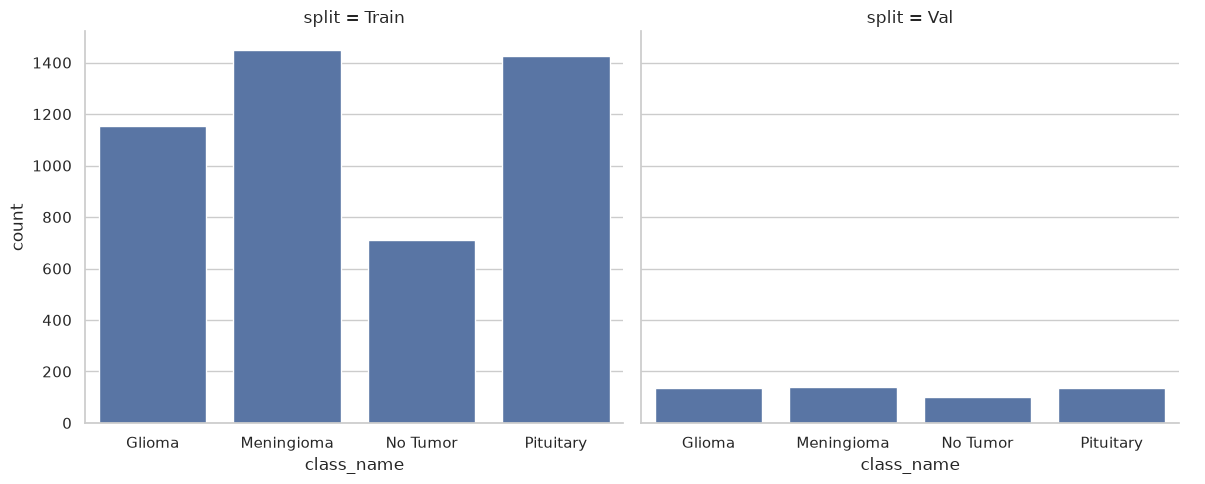

In [2]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

dataset_dir = Path("../data/classification")
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

records = []

for split in ["Train", "Val"]:
    split_dir = dataset_dir / split

    if not split_dir.exists():
        print(f"Directory not found: {split_dir.resolve()}")
        continue

    for class_dir in split_dir.iterdir():
        images_dir = class_dir / "images"

        if not images_dir.is_dir():
            continue

        for image_path in images_dir.iterdir():
            if image_path.is_file() and image_path.suffix.lower() in extensions:
                records.append({
                    "split": split,
                    "class_name": class_dir.name,
                })

df = pd.DataFrame(records)

if df.empty:
    print(f"No images found. Check this path: {dataset_dir.resolve()}")
else:
    print(df.groupby(["split", "class_name"]).size())

    sns.set_theme(style="whitegrid")
    sns.catplot(
        data=df,
        x="class_name",
        kind="count",
        col="split",
        order=sorted(df["class_name"].unique()),
        height=5,
        aspect=1.2,
    )

    plt.show()

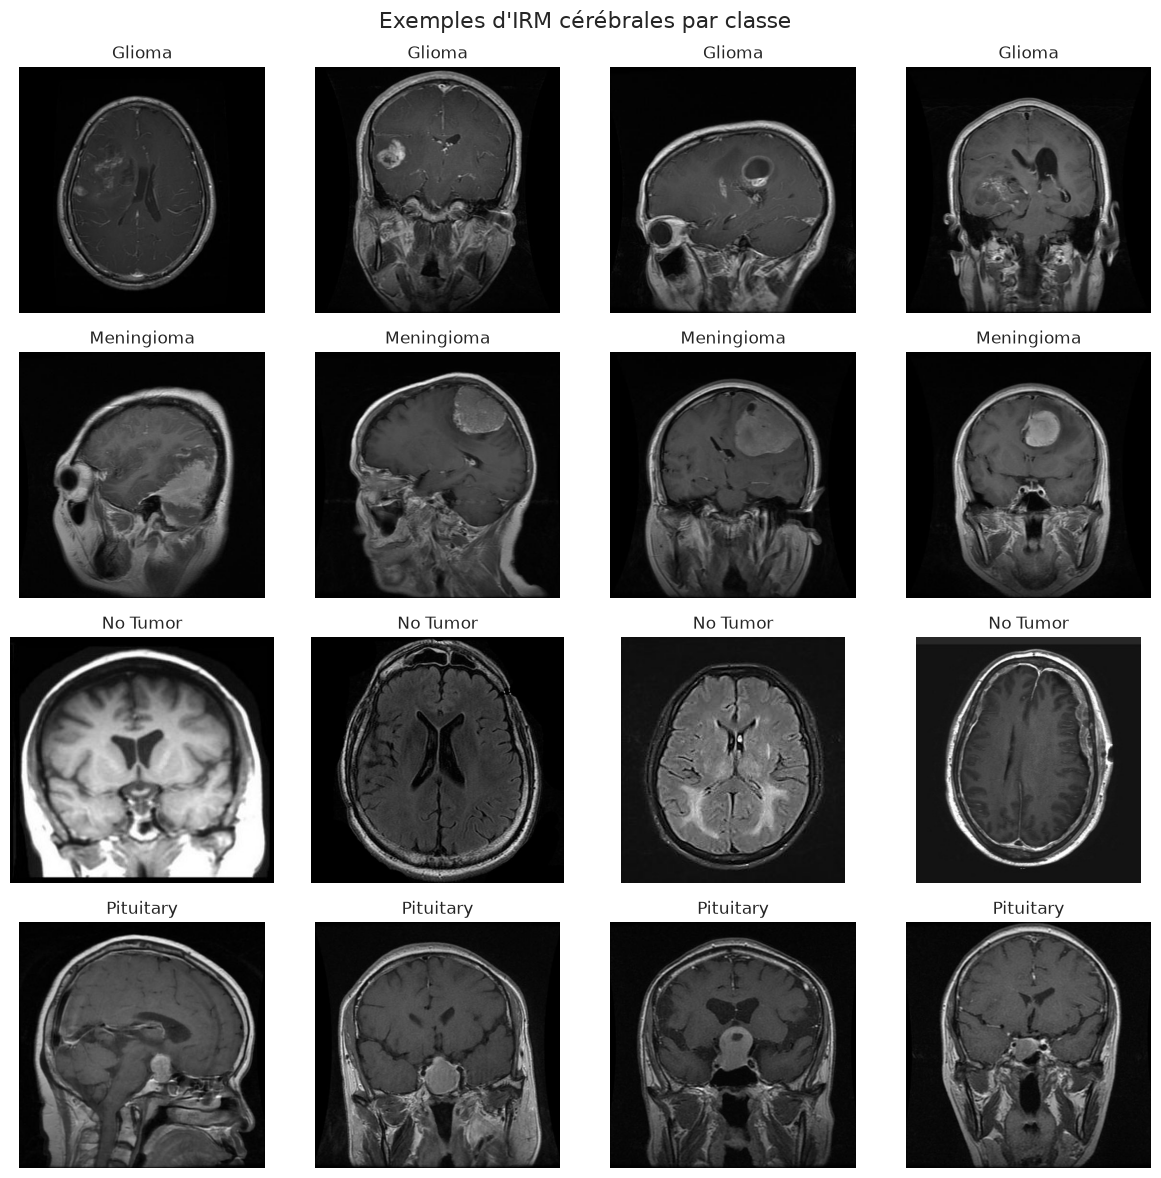

In [3]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

DATASET_DIR = Path("../data/classification/Train")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
N_IMAGES = 4

classes = sorted(
    folder.name
    for folder in DATASET_DIR.iterdir()
    if folder.is_dir() and (folder / "images").is_dir()
)

fig, axes = plt.subplots(
    len(classes),
    N_IMAGES,
    figsize=(12, 3 * len(classes))
)

for row, class_name in enumerate(classes):
    images_dir = DATASET_DIR / class_name / "images"

    image_paths = [
        path for path in images_dir.iterdir()
        if path.is_file() and path.suffix.lower() in EXTENSIONS
    ]

    samples = random.sample(
        image_paths,
        min(N_IMAGES, len(image_paths))
    )

    for col in range(N_IMAGES):
        ax = axes[row, col] if len(classes) > 1 else axes[col]

        if col < len(samples):
            with Image.open(samples[col]) as image:
                ax.imshow(image.convert("RGB"))

            ax.set_title(class_name)
        else:
            ax.set_visible(False)

        ax.axis("off")

plt.suptitle("Exemples d'IRM cérébrales par classe", fontsize=16)
plt.tight_layout()
plt.show()

In [4]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter
import shutil

SOURCE_DIR = Path("../data/classification")
OUTPUT_DIR = Path("../data/classification_split")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

records = []

for split in ["Train", "Val"]:
    split_dir = SOURCE_DIR / split

    if not split_dir.exists():
        continue

    for class_dir in split_dir.iterdir():
        images_dir = class_dir / "images"

        if not images_dir.is_dir():
            continue

        for path in images_dir.iterdir():
            if path.is_file() and path.suffix.lower() in EXTENSIONS:
                records.append((path, class_dir.name))

if not records:
    raise ValueError(f"Aucune image trouvée dans {SOURCE_DIR.resolve()}")

paths = [str(path) for path, label in records]
labels = [label for path, label in records]


train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels,
)


val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels,
)

splits = {
    "Train": (train_paths, train_labels),
    "Validation": (val_paths, val_labels),
    "Test": (test_paths, test_labels),
}

for split_name, (split_paths, split_labels) in splits.items():
    for image_path, class_name in zip(split_paths, split_labels):
        destination_dir = OUTPUT_DIR / split_name / class_name / "images"
        destination_dir.mkdir(parents=True, exist_ok=True)

        shutil.copy2(
            image_path,
            destination_dir / Path(image_path).name,
        )

print(f"Total d'images : {len(records)}")

for split_name, (split_paths, _) in splits.items():
    percentage = len(split_paths) / len(records) * 100
    print(f"{split_name}: {len(split_paths)} images ({percentage:.2f} %)")

print(f"\nDataset créé dans : {OUTPUT_DIR.resolve()}")

Total d'images : 5249
Train: 3674 images (69.99 %)
Validation: 787 images (14.99 %)
Test: 788 images (15.01 %)

Dataset créé dans : /home/alaric/Desktop/studies/projects/DL/brain-tumor-classification-deep-learning/data/classification_split


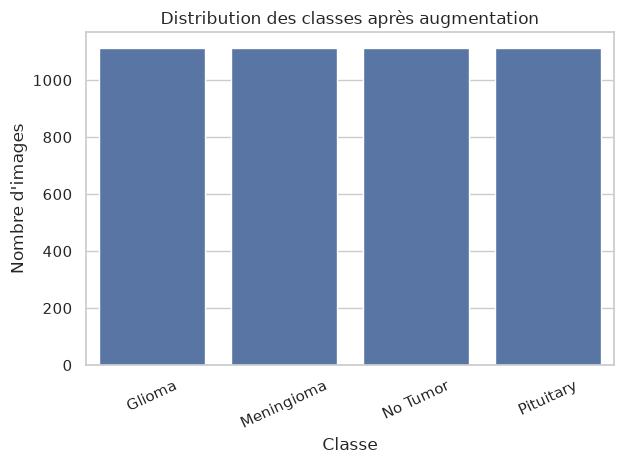

In [5]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

train_dir = Path("../data/classification_split/Train")
records = []

for class_dir in train_dir.iterdir():
    images_dir = class_dir / "images"

    if images_dir.is_dir():
        for path in images_dir.iterdir():
            if path.is_file() and path.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".bmp"
            }:
                records.append({"class_name": class_dir.name})

df = pd.DataFrame(records)

sns.countplot(data=df, x="class_name", order=sorted(df["class_name"].unique()))
plt.title("Distribution des classes après augmentation")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()